**SVM**

First 5 rows:
   Age   Fare  Pclass  Survived
0   22   7.25       3         0
1   38  71.28       1         1
2   26   7.92       3         1
3   35  53.10       1         1
4   35   8.05       3         0

Dataset Shape:
(15, 4)

Features after scaling:
[[-0.48468955 -0.93281491]
 [ 0.55393092  2.444582  ]
 [-0.22503444 -0.89747435]
 [ 0.35918958  1.48563969]
 [ 0.35918958 -0.89061723]]

Training samples: 12
Testing samples: 3

Kernel: linear
Accuracy: 0.3333333333333333

Kernel: poly
Accuracy: 0.3333333333333333

Kernel: rbf
Accuracy: 0.6666666666666666


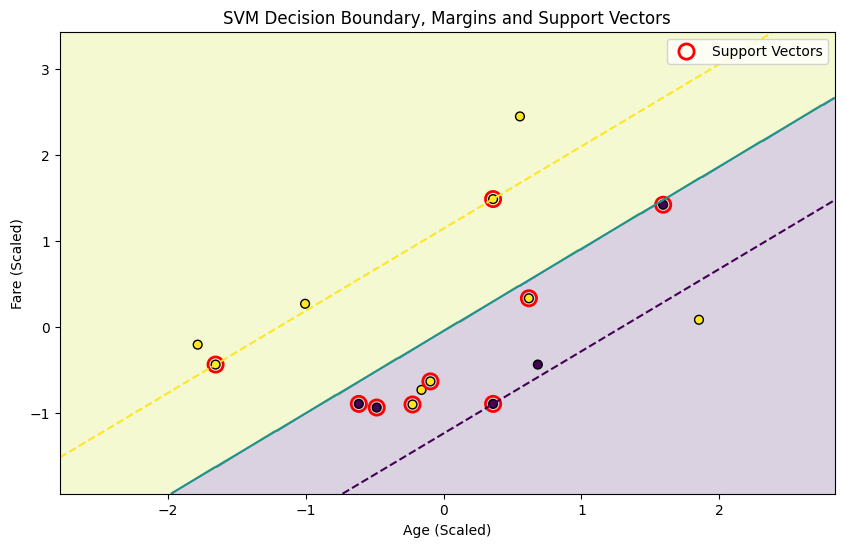

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(



Best Parameters:
{'C': 1, 'gamma': 10}

Best Cross-Validation Accuracy:
0.8333333333333333

Final Test Accuracy:
0.6666666666666666


In [ ]:
# SVM Binary Classification - Titanic Dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score


df = pd.read_csv("/content/drive/MyDrive/ML/Titanic_SVM_Binary_Classification.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)


# 2. Data Preprocessing

# Use Age and Fare as features
X = df[["Age", "Fare"]]

# Target variable
y = df["Survived"]

# Remove missing values
data = pd.concat([X, y], axis=1).dropna()

X = data[["Age", "Fare"]]
y = data["Survived"]

# Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFeatures after scaling:")
print(X_scaled[:5])


# 3. Split Data

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 4. Train SVM with Different Kernels

kernels = ["linear", "poly", "rbf"]

for kernel in kernels:

    model = SVC(kernel=kernel)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    print("\nKernel:", kernel)
    print("Accuracy:", accuracy)

# 5. Visualize Support Vectors and Margins

# Train Linear SVM for visualization
svm = SVC(kernel="linear")
svm.fit(X_train, y_train)

# Create mesh grid
x_min = X_scaled[:, 0].min() - 1
x_max = X_scaled[:, 0].max() + 1

y_min = X_scaled[:, 1].min() - 1
y_max = X_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict grid points
grid = np.c_[xx.ravel(), yy.ravel()]
Z = svm.predict(grid)
Z = Z.reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(10, 6))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2
)

# Plot data points
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y,
    edgecolors="k",
    s=40
)

# Highlight support vectors
plt.scatter(
    svm.support_vectors_[:, 0],
    svm.support_vectors_[:, 1],
    s=120,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Support Vectors"
)

# Decision boundary and margins
decision_values = svm.decision_function(grid)
decision_values = decision_values.reshape(xx.shape)

plt.contour(
    xx,
    yy,
    decision_values,
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"]
)

plt.xlabel("Age (Scaled)")
plt.ylabel("Fare (Scaled)")
plt.title("SVM Decision Boundary, Margins and Support Vectors")
plt.legend()
plt.show()

# 6. Hyperparameter Tuning using GridSearchCV

# RBF SVM
rbf_svm = SVC(kernel="rbf")

# Parameter grid
param_grid = {
    "C": [0.1, 1, 10],
    "gamma": [0.1, 1, 10]
}

# GridSearchCV
grid_search = GridSearchCV(
    rbf_svm,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

# Best parameters
print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(grid_search.best_score_)


# Train model with best parameters
best_model = grid_search.best_estimator_

# Prediction
y_pred_best = best_model.predict(X_test)

# Test accuracy
best_accuracy = accuracy_score(y_test, y_pred_best)

print("\nFinal Test Accuracy:")
print(best_accuracy)